# Solutions to the exercises of Chapter 12

Sample solutions for [Chapter 12, Phase separation](../../notebooks/part3_soft_materials/12_phase_separation.ipynb).

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import quad
from scipy.optimize import brentq

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

def f(p, chi):
    return p * np.log(p) + (1 - p) * np.log(1 - p) + chi * p * (1 - p)

def df(p, chi):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return np.log(p / (1 - p)) + chi * (1 - 2 * p)

def binodal(chi):
    return brentq(lambda p: df(p, chi), 1e-12, 0.5 - 1e-9)

## Exercise 1. Near the critical point

In [2]:
psi, chiN = sp.symbols("psi chiN", real=True)
p_ = sp.Rational(1, 2) + psi
f_sym = p_ * sp.log(p_) + (1 - p_) * sp.log(1 - p_) + chiN * p_ * (1 - p_)
expansion = sp.series(f_sym, psi, 0, 5).removeO()
print("f(1/2 + psi) =", sp.expand(sp.simplify(expansion)))

f(1/2 + psi) = -chiN*psi**2 + chiN/4 + 4*psi**4/3 + 2*psi**2 - log(2)


With $\varepsilon = \chi N - 2$, the free energy is $f \simeq \text{const} - \varepsilon\psi^2 + \tfrac43\psi^4$, a double well.

* *Binodal.* $f'(\psi_e) = -2\varepsilon\psi_e + \tfrac{16}{3}\psi_e^3 = 0$ gives $\psi_e^2 = \tfrac38\varepsilon$.
* *Interface.* $\Delta f = \tfrac43(\psi^2 - \psi_e^2)^2$, so $\psi' = \sqrt{8/3}\,(\psi_e^2 - \psi^2)$, whose solution is
  $\psi = \psi_e\tanh(z/w)$ with $w = 1/(\sqrt{8/3}\,\psi_e) = \varepsilon^{-1/2}$.
* *Tension.* $\gamma = \int\sqrt{2\Delta f}\,d\psi = \sqrt{8/3}\int_{-\psi_e}^{\psi_e}(\psi_e^2 - \psi^2)\,d\psi = \sqrt{8/3}\,\tfrac43\psi_e^3 = \tfrac12\varepsilon^{3/2}$.

The width diverges and the tension vanishes at the critical point, as
$(T_c - T)^{-1/2}$ and $(T_c - T)^{3/2}$ when $\chi N - 2 \propto T_c - T$: the results of Cahn and
Hilliard.

In [3]:
print("  chi N     psi_e exact   quartic     gamma exact    quartic     ratio")
rows = []
for chi in (2.01, 2.05, 2.1, 2.2, 2.5, 3.0):
    pe = binodal(chi)
    gamma = quad(lambda p: math.sqrt(max(2 * (f(p, chi) - f(pe, chi)), 0.0)), pe, 1 - pe, limit=200)[0]
    eps = chi - 2
    rows.append((chi, 0.5 - pe, math.sqrt(3 * eps / 8), gamma, 0.5 * eps**1.5))
    print(f"  {chi:5.2f}     {0.5 - pe:.5f}     {math.sqrt(3 * eps / 8):.5f}     {gamma:.3e}    {0.5 * eps**1.5:.3e}    {gamma / (0.5 * eps**1.5):.4f}")

  chi N     psi_e exact   quartic     gamma exact    quartic     ratio
   2.01     0.06096     0.06124     4.966e-04    5.000e-04    0.9931
   2.05     0.13393     0.13693     5.403e-03    5.590e-03    0.9665
   2.10     0.18535     0.19365     1.478e-02    1.581e-02    0.9350
   2.20     0.25147     0.27386     3.923e-02    4.472e-02    0.8772
   2.50     0.35521     0.43301     1.303e-01    1.768e-01    0.7368
   3.00     0.42928     0.61237     2.883e-01    5.000e-01    0.5765


The quartic expansion is accurate within a few per cent for $\chi N - 2 < 0.05$ and
overestimates the tension by 14 % at $\chi N = 2.2$; deeper quenches need the full
logarithms.

## Exercise 2. The one-mode trial in closed form

With $\psi = a\cos qx$ and the quartic free energy, $\langle f'(\psi)\cos qx\rangle = -\varepsilon a + \tfrac{16}{3}a^3\langle\cos^4qx\rangle = -\varepsilon a + 2a^3$,
and Eq. (12.12) becomes

$$ \dot a = -2q^2\Big[-\varepsilon a + 2a^3 + \tfrac12q^2a\Big] . $$

The linear part gives $\omega = 2q^2(\varepsilon - q^2/2) = -q^2(f'' + q^2)$, since $f''(\tfrac12) = -2\varepsilon$: the
linear theory. The amplitude saturates at

$$ a_\infty^2 = \frac{2\varepsilon - q^2}{4} , $$

which is largest for long waves, $a_\infty^2 \to \varepsilon/2$. That is close to the first Fourier
coefficient of a square wave between $\pm\psi_e$, $(4/\pi)\psi_e$, whose square is $0.61\,\varepsilon$:
for long waves the pattern becomes two flat phases, and one mode is only the
best sine wave that fits them. At the fastest wave number, $q_m^2 = \varepsilon$, $a_\infty^2 = \varepsilon/4$.

In [4]:
chi = 2.2
eps = chi - 2
q = math.sqrt(eps)
nx = 512
xg = np.arange(nx) * 2 * np.pi / (q * nx)
final = on.cahn_hilliard_spectral(0.5 + 0.01 * np.cos(q * xg), 2 * np.pi / q, [0.0, 400.0], lambda p: df(p, chi), 0.02)[-1]
a_num = 2 * np.real(np.fft.rfft(final))[1] / nx
a_fh = brentq(lambda a: np.mean(df(0.5 + a * np.cos(q * xg), chi) * np.cos(q * xg)) + 0.5 * q * q * a, 1e-3, 0.49)
print(f"chi N = {chi}, q = q_m:  closed form a = {math.sqrt(eps / 4):.4f},  one-mode trial with Flory-Huggins {a_fh:.4f},"
      f"  numerical {a_num:.4f}")

chi N = 2.2, q = q_m:  closed form a = 0.2236,  one-mode trial with Flory-Huggins 0.2130,  numerical 0.2172


The closed form is 3 % above the numerical amplitude; most of the difference
comes from the quartic expansion, which overestimates the depth of the double well
at $\chi N = 2.2$ (Exercise 1), not from the one-mode trial.

## Exercise 3. An off-critical quench

For $\chi N = 2.5$ the spinodal (12.6) is at $\phi(1 - \phi) = 1/5$, $\phi = 0.276$, so $\bar\phi = 0.35$ is inside
it: $f''(0.35) = 1/0.2275 - 5 = -0.60$, and $q_m = (0.60/2)^{1/2} = 0.55$, smaller than at the critical
composition. The lever rule gives the fraction of the A-rich phase,
$(\bar\phi - \phi_e)/(1 - 2\phi_e) = 0.29$.

f''(0.35) = -0.604,  q_m = 0.550,  fraction of the A-rich phase 0.289


t: [  50  100  200  400  800 1600 3200 6400]
domain size: [10.7 12.1 13.7 15.9 19.4 22.3 25.6 30.5]
local exponent: [0.178 0.17  0.219 0.284 0.204 0.197 0.252]


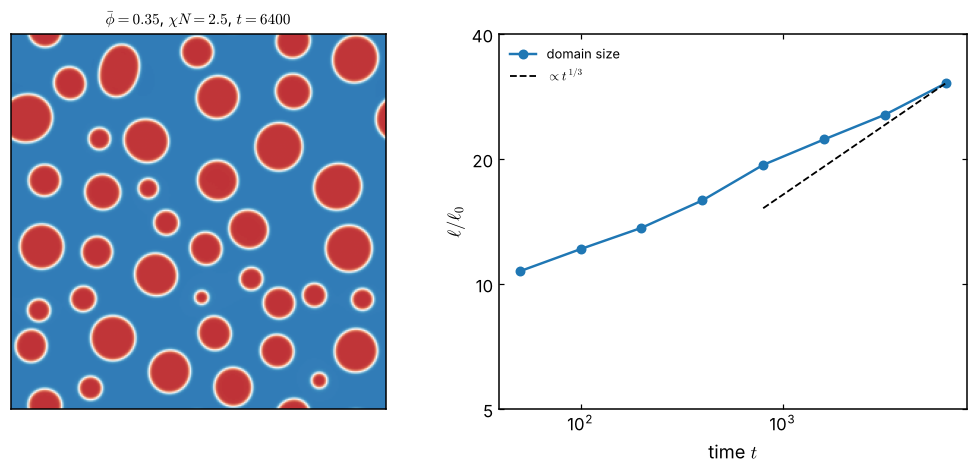

In [5]:
chi, pbar, n, box, dt = 2.5, 0.35, 256, 256.0, 0.5
pe = binodal(chi)
print(f"f''(0.35) = {1 / (pbar * (1 - pbar)) - 2 * chi:.3f},  q_m = {math.sqrt(-(1 / (pbar * (1 - pbar)) - 2 * chi) / 2):.3f},"
      f"  fraction of the A-rich phase {(pbar - pe) / (1 - 2 * pe):.3f}")
t_off = np.array([0, 50, 100, 200, 400, 800, 1600, 3200, 6400])
rng = np.random.default_rng(3)
snaps = on.cahn_hilliard_spectral(pbar + 0.01 * rng.standard_normal((n, n)), box, t_off, lambda p: df(p, chi), dt)
k = 2 * np.pi * np.fft.fftfreq(n, d=box / n)
kk = np.sqrt(np.add.outer(k**2, k**2))
sizes = []
for p in snaps[1:]:
    s = np.abs(np.fft.fft2(p - p.mean())) ** 2
    sizes.append(2 * np.pi * s.sum() / (s * kk).sum())
sizes = np.array(sizes)
local = np.diff(np.log(sizes)) / np.diff(np.log(t_off[1:]))
print("t:", t_off[1:])
print("domain size:", np.round(sizes, 1))
print("local exponent:", np.round(local, 3))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.2))
ax1.imshow(snaps[-1].T, origin="lower", cmap="RdBu_r", vmin=0, vmax=1, extent=(0, box, 0, box))
ax1.set_xticks([]); ax1.set_yticks([]); ax1.set_title(r"$\bar\phi = 0.35$, $\chi N = 2.5$, $t = 6400$", fontsize=10)
ax2.loglog(t_off[1:], sizes, "C0o-", label="domain size")
tt = np.array([800, 6400])
ax2.loglog(tt, sizes[-1] * (tt / tt[-1]) ** (1 / 3), "k--", lw=1.2, label=r"$\propto t^{1/3}$")
ax2.set_xlabel("time $t$"); ax2.set_ylabel(r"$\ell/\ell_0$"); ax2.set_yticks([5, 10, 20, 40], ["5", "10", "20", "40"]); ax2.minorticks_off()
ax2.legend(loc="upper left", fontsize=8.5)
plt.show()

**Figure S12.1.** Off-critical quench: droplets of the A-rich phase in a matrix of the
B-rich phase, and their growth.

The pattern is no longer bicontinuous: the minority phase breaks up into droplets,
which then ripen, the small ones dissolving into the matrix and the large ones
growing. This is the situation that Lifshitz and Slyozov analysed. The scaling
argument is unchanged: the interfacial area per volume is still of order $1/\ell$ (with
a factor set by the volume fraction of droplets), and material still has to travel
a distance of order $\ell$, now from small droplets to large ones through the matrix.
The measured local exponent fluctuates between 0.18 and 0.28, below $1/3$. Ripening
of droplets approaches its asymptotic law even more slowly than the bicontinuous
pattern, and the box holds only a few dozen droplets, so the statistics are poor.

## Exercise 4. Polymer blends

With $\kappa = k_BT\,b^2/18v\phi(1 - \phi)$, $\ell_0 = (\kappa vN/k_BT)^{1/2} = b\,[N/18\phi(1 - \phi)]^{1/2}$, which at
$\phi = \tfrac12$ is $b\,(2N/9)^{1/2}$. The fastest wavelength is $2\pi/q_m = 2\pi\ell_0/(\chi N - 2)^{1/2}$, since
$-f''(\tfrac12) = 2(\chi N - 2)$.

In [6]:
b = 0.7e-9
for N in (1, 1000):
    l0 = b * math.sqrt(2 * N / 9)
    waves = [2 * math.pi * l0 / math.sqrt(chi - 2) for chi in (2.5, 2.05)]
    print(f"N = {N:5d}:  l0 = {l0 * 1e9:6.2f} nm;  fastest wavelength {waves[0] * 1e9:7.1f} nm (chi N = 2.5), "
          f"{waves[1] * 1e9:7.1f} nm (chi N = 2.05)")

N =     1:  l0 =   0.33 nm;  fastest wavelength     2.9 nm (chi N = 2.5),     9.3 nm (chi N = 2.05)
N =  1000:  l0 =  10.43 nm;  fastest wavelength    92.7 nm (chi N = 2.5),   293.2 nm (chi N = 2.05)


The length scale of a polymer blend is the size of a chain, $b\sqrt N$, not the size of
a segment. For $N = 1000$ the fastest wavelength is about 0.1 µm after a moderate
quench and 0.3 µm close to the critical point, the range of visible light. For small
molecules it is a few nanometres, which light cannot resolve. Polymer blends are
also slow: the mobility of interdiffusion falls with chain length, so the early
stage lasts long enough to be followed. This is why the linear theory of Cahn
was first tested in detail on polymer blends.